# Classification Model Guide




The dataset we are going to use contains information about diamonds. The features are:

- price price in US dollars (\$326--\$18,823)

- carat weight of the diamond (0.2--5.01)

- cut quality of the cut (Fair, Good, Very Good, Premium, Ideal)

- color diamond colour, from J (worst) to D (best)

- clarity a measurement of how clear the diamond is (I1 (worst), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (best))

- x length in mm (0--10.74)

- y width in mm (0--58.9)

- z depth in mm (0--31.8)

- depth total depth percentage = z / mean(x, y) = 2 * z / (x + y) (43--79)

- table width of top of diamond relative to widest point (43--95)

In this problem, our target variable is going to be **cut**. This way, the aim will be to evaluate, as an expert would do, the quality of the cut of a diamond knowing the other features. 

As there are several possible values for cut, it is a multiclass classification problem.

The first thing we have to do is install the packages we are going to use

In [31]:
!pip install pandas scikit-learn numpy matplotlib seaborn


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Load data

The first thing we have to do is to load the data into a pandas Dataframe

In [32]:
import pandas as pd

df = pd.read_csv("diamonds.csv")

## 2. EDA

### 2.1. General information

Now we can take a look and see what the dataset look s like

In [33]:
df.head(10)

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,b'Ideal',b'E',b'SI2',61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,b'Premium',b'E',b'SI1',59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,b'Good',b'E',b'VS1',56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,b'Premium',b'I',b'VS2',62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,b'Good',b'J',b'SI2',63.3,58.0,335.0,4.34,4.35,2.75
5,0.24,b'Very Good',b'J',b'VVS2',62.8,57.0,336.0,3.94,3.96,2.48
6,0.24,b'Very Good',b'I',b'VVS1',62.3,57.0,336.0,3.95,3.98,2.47
7,0.26,b'Very Good',b'H',b'SI1',61.9,55.0,337.0,4.07,4.11,2.53
8,0.22,b'Fair',b'E',b'VS2',65.1,61.0,337.0,3.87,3.78,2.49
9,0.23,b'Very Good',b'H',b'VS1',59.4,61.0,338.0,4.00,4.05,2.39


For taking an overview, we can use Dataframe.info()

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  float64
 7   'x'      53940 non-null  float64
 8   'y'      53940 non-null  float64
 9   'z'      53940 non-null  float64
dtypes: float64(7), str(3)
memory usage: 4.1 MB


We can see that there are 7 numeric features and 3 categoric features (including the target variable). 

However, we can see that the 3 features follow a logic order (see feature description), so they are, in fact, ordinal features. 

For general stadistics, use Dataframe.describe()

In [35]:
df.describe()

,carat,depth,table,price,'x','y','z'
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


Here we have some information we might need later

In [36]:
df.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
'x'        0
'y'        0
'z'        0
dtype: int64

Here we see that there are not null values at all. This simplifies the preprocessing and feature engineering, since value imputation is not needed. 

### 2.2 Univariate analysis 

#### Distributions

The objective with this analysis is to analyze and understand every single feature 

In [37]:
# We are going to focus first on numeric features

# We select only float64 because in df.info() we saw that all numeric features were float64
numeric_features = df.select_dtypes(include="float64").columns.tolist()


Now we are going to create histograms for every variable but first we need to do some configuration of matplotlib and seaborn

In [38]:
# Matplotlib and seaborn config

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12,8)
plt.rcParams['font.size'] = 12

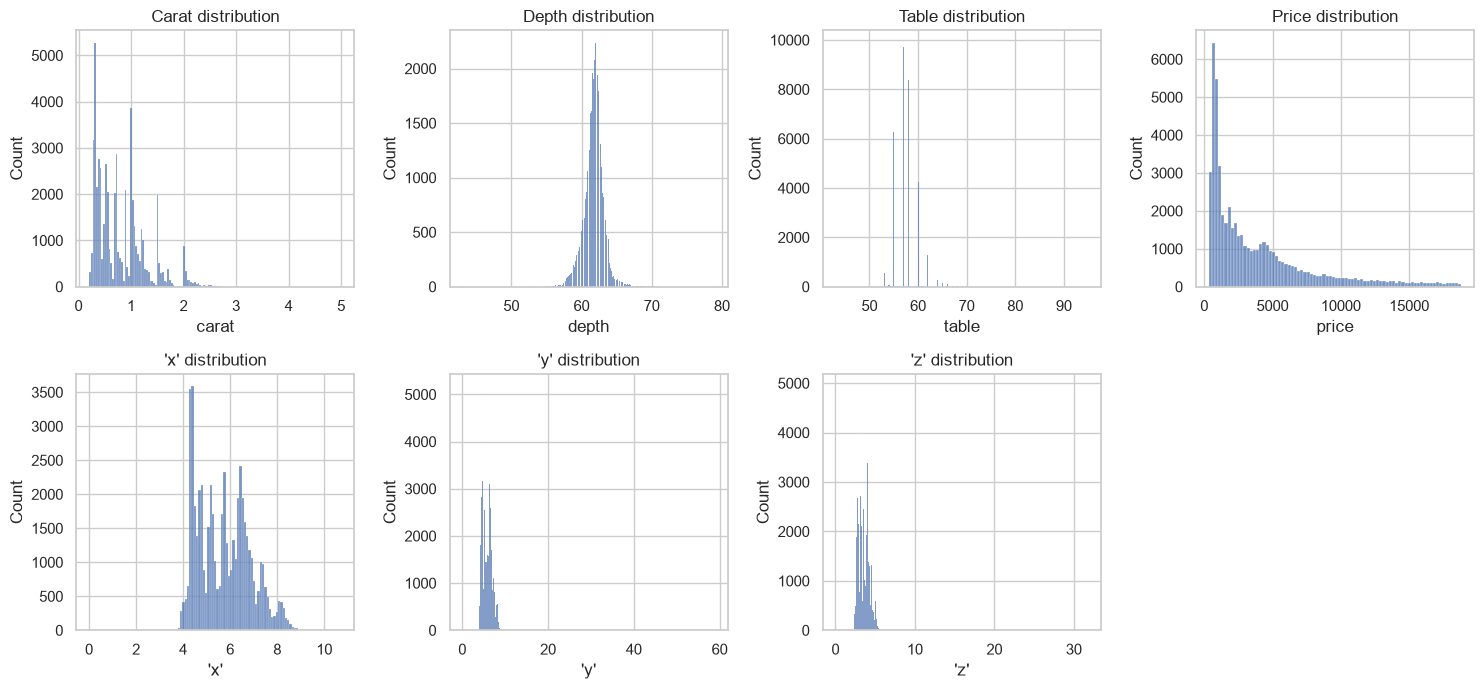

In [39]:
plt.figure(figsize=(15,10))
for i, col in enumerate(numeric_features, 1):
    plt.subplot(3, 4, i)
    sns.histplot(df[col], kde=False)
    plt.title(f"{col.capitalize()} distribution")

plt.tight_layout()
plt.show()


As we can see, there are some of the features that follow a charasteristic ditribution that can give us valuable information. For example, an easy one can be **price**. As we can see, it follows a lognormal distribution. This give us some information, such as noticing that there are much more cheap diamonds than expensive ones. This matches with the **carat** distribution, that confirms the theory, as there are much more diamonds with low carat than with high carat. 

This kinds of things are important in order to decide which model is the best, as some of them doesn't perform well with some kinds of distributions, or maybe some preprocessing is needed. 

#### Ordinal features

Now we can visualize ordinal features. It is important to remember that we have to define explicitly the order. 

In [40]:
# Select the ordinal features
ordinal_features = df.select_dtypes(include="str").columns.tolist()

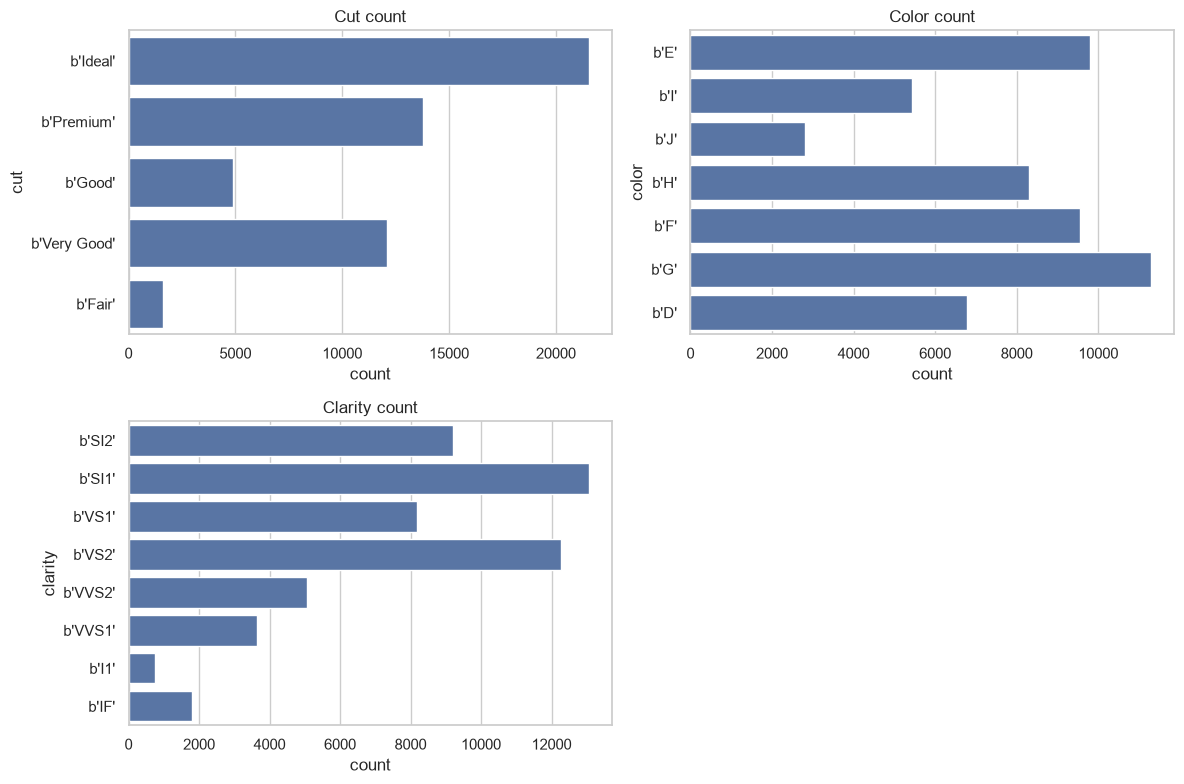

In [41]:
for i, col in enumerate(ordinal_features, 1):
    plt.subplot(2,2, i)
    sns.countplot(df[col])
    plt.title(f"{col.capitalize()} count")

plt.tight_layout()
plt.show()

Here we can notice, for example, that our target variable **cut** is imbalanced, as it has much more instances of ideal than fair. So we are going to see this as percentages

In [42]:
(df["cut"].value_counts(normalize=True) * 100).round(2)

cut
b'Ideal'        39.95
b'Premium'      25.57
b'Very Good'    22.40
b'Good'          9.10
b'Fair'          2.98
Name: proportion, dtype: float64

The different is considerable, but, if we look at the graphic above, we see that even the fair class with less than 3% is about 2000 instances aproximately. We will se later, but maybe it is not necessary to preprocess data for balancing classes. 

#### Outliers

Another important thing is to see the outliers. That means, values that are too far away from the rest of the values. 

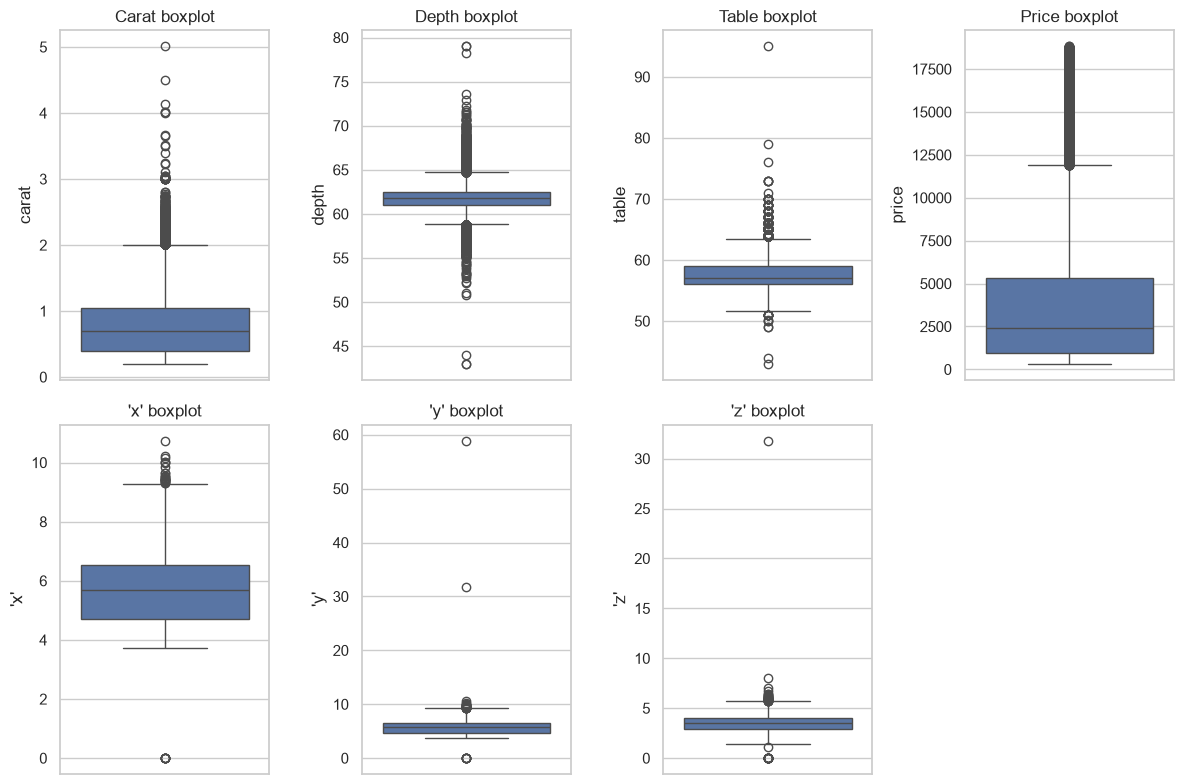

In [43]:
for i, col in enumerate(numeric_features, 1):
    plt.subplot(2,4, i)
    sns.boxplot(y=df[col])
    plt.title(f"{col.capitalize()} boxplot")

plt.tight_layout()
plt.show()

Here, for example we can see that for price and carat, the 50% is condensed in very low values and there are a few of instnaces then that really stand out

Another useful analysis to do when doing univariate analysis is a time-series trend analysis. However, in this case, it has no sense to do it because there's no time dimension

### 2.3. Bivariate analysis

#### Correlation matrix

In order to see the correlation of each variable with each other, we are going to build a correlation matrix

          carat     depth     table     price       'x'       'y'       'z'
carat  1.000000  0.028224  0.181618  0.921591  0.975094  0.951722  0.953387
depth  0.028224  1.000000 -0.295779 -0.010647 -0.025289 -0.029341  0.094924
table  0.181618 -0.295779  1.000000  0.127134  0.195344  0.183760  0.150929
price  0.921591 -0.010647  0.127134  1.000000  0.884435  0.865421  0.861249
'x'    0.975094 -0.025289  0.195344  0.884435  1.000000  0.974701  0.970772
'y'    0.951722 -0.029341  0.183760  0.865421  0.974701  1.000000  0.952006
'z'    0.953387  0.094924  0.150929  0.861249  0.970772  0.952006  1.000000


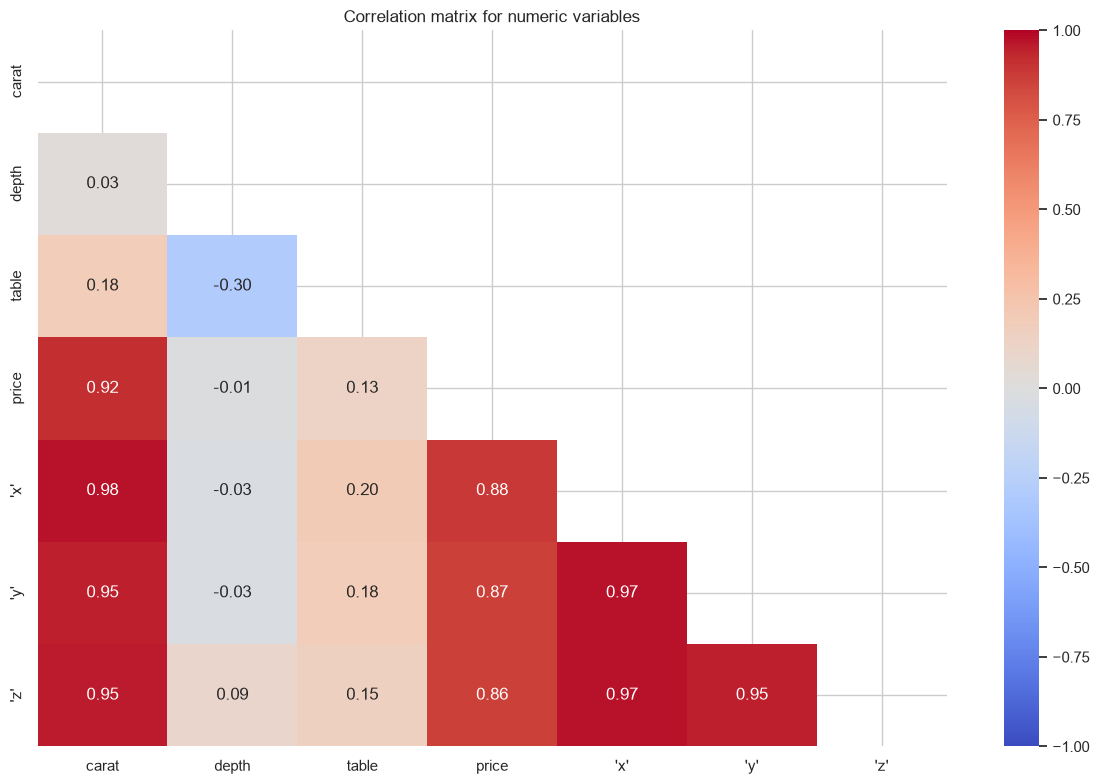

In [44]:
import numpy as np

corr = df[numeric_features].corr()
print(corr)
mask = np.triu(np.ones_like(corr, dtype=bool)) # Only shows the half
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix for numeric variables")
plt.tight_layout()
plt.show()

Here we can see that, for example, carat is highly correlationated with price and the dimensions, and also dimensions are highly correlationated between them. 

#### Scatterplots

Para analizar cómo es la relación entre las variables más correlacionadas, usaremos scatterplots con el pro

In order to analyze how is the relationship between the most correlated variables, we will use scatterplots with the purpose of visualizing that relationship, and see if it is linear, non-linear...

Text(0.5, 1.0, 'Depth vs Table scatterplot')

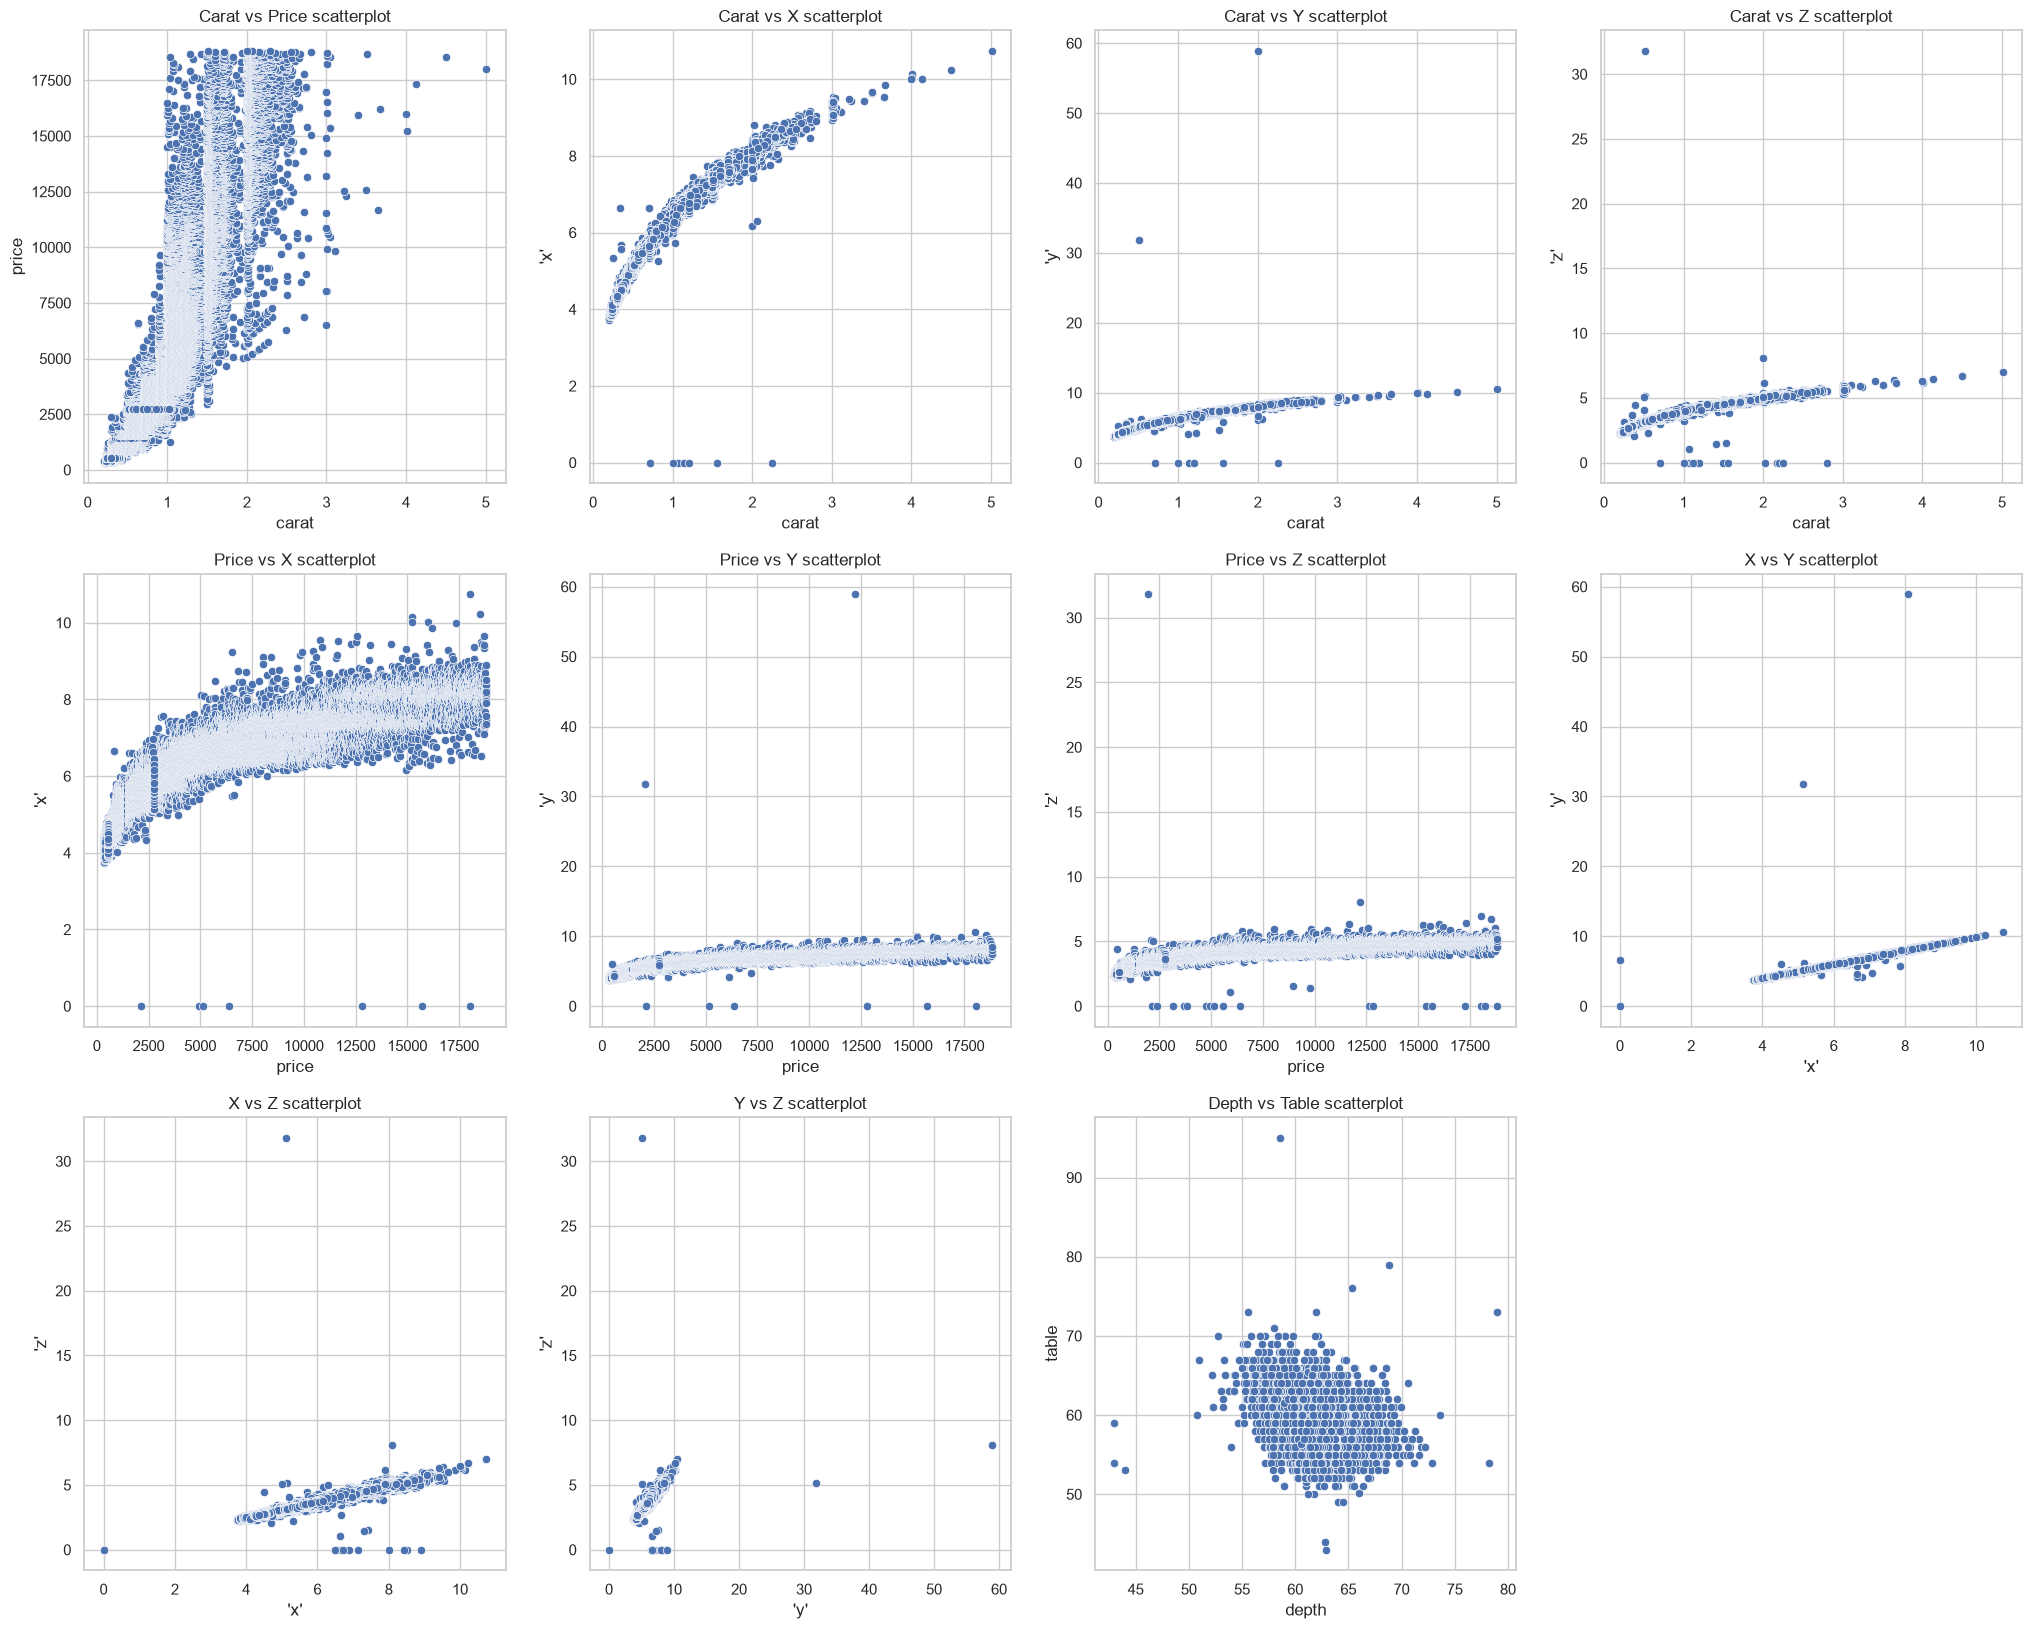

In [45]:
# The first two variables to analyze is carat and price, that have a strong correlation
plt.figure(figsize=(25,20))
plt.subplot(3,4,1)
sns.scatterplot(df, x='carat', y='price')
plt.title("Carat vs Price scatterplot")

# Then we are going to do the same with x, y and z
plt.subplot(3,4,2)
sns.scatterplot(df, x='carat', y='\'x\'')
plt.title("Carat vs X scatterplot")

plt.subplot(3,4,3)
sns.scatterplot(df, x='carat', y='\'y\'')
plt.title("Carat vs Y scatterplot")

plt.subplot(3,4,4)
sns.scatterplot(df, x='carat', y='\'z\'')
plt.title("Carat vs Z scatterplot")


# Price also has a strong relationship with x,y and z
plt.subplot(3,4,5)
sns.scatterplot(df, x='price', y='\'x\'')
plt.title("Price vs X scatterplot")

plt.subplot(3,4,6)
sns.scatterplot(df, x='price', y='\'y\'')
plt.title("Price vs Y scatterplot")

plt.subplot(3,4,7)
sns.scatterplot(df, x='price', y='\'z\'')
plt.title("Price vs Z scatterplot")

# It is also interesting the relationship between variables x,y,z
plt.subplot(3,4,8)
sns.scatterplot(df, x='\'x\'', y='\'y\'')
plt.title("X vs Y scatterplot")

plt.subplot(3,4,9)
sns.scatterplot(df, x='\'x\'', y='\'z\'')
plt.title("X vs Z scatterplot")

plt.subplot(3,4,10)
sns.scatterplot(df, x='\'y\'', y='\'z\'')
plt.title("Y vs Z scatterplot")

# Finally, we will study the negative correlation between Depth and Table
plt.subplot(3,4,11)
sns.scatterplot(df, x='depth', y='table')
plt.title("Depth vs Table scatterplot")

From these scatterplots we can extract several conclusions. A few of them could be
- Price cannot be explained just with carat, as for the same carat (e.g., carat = 2), there are prices since 5000 up to 18000
- When we compare carat vs x,y,x we realize that they follow what seems to be standard sizes
- However, we can see something strange in some of the scatterplots with the 'x', 'y' and 'z' variables. Sometimes, there are some points that indicate that x or y or z is equal to 0, and obviously, there's no chance that a diamond measures 0 on some of the axis. This values need to be treated as they are errors
- Also, we can identify noise, for example, in the 3rd scatterplot, carat=2 and y=59
- We can also explain the strong correlation of x,y and z with the symmetry and shape of a diamond. X and Y have to be almost equal, and Z must be proportional

In order to visualize all relations, we can use pairplot

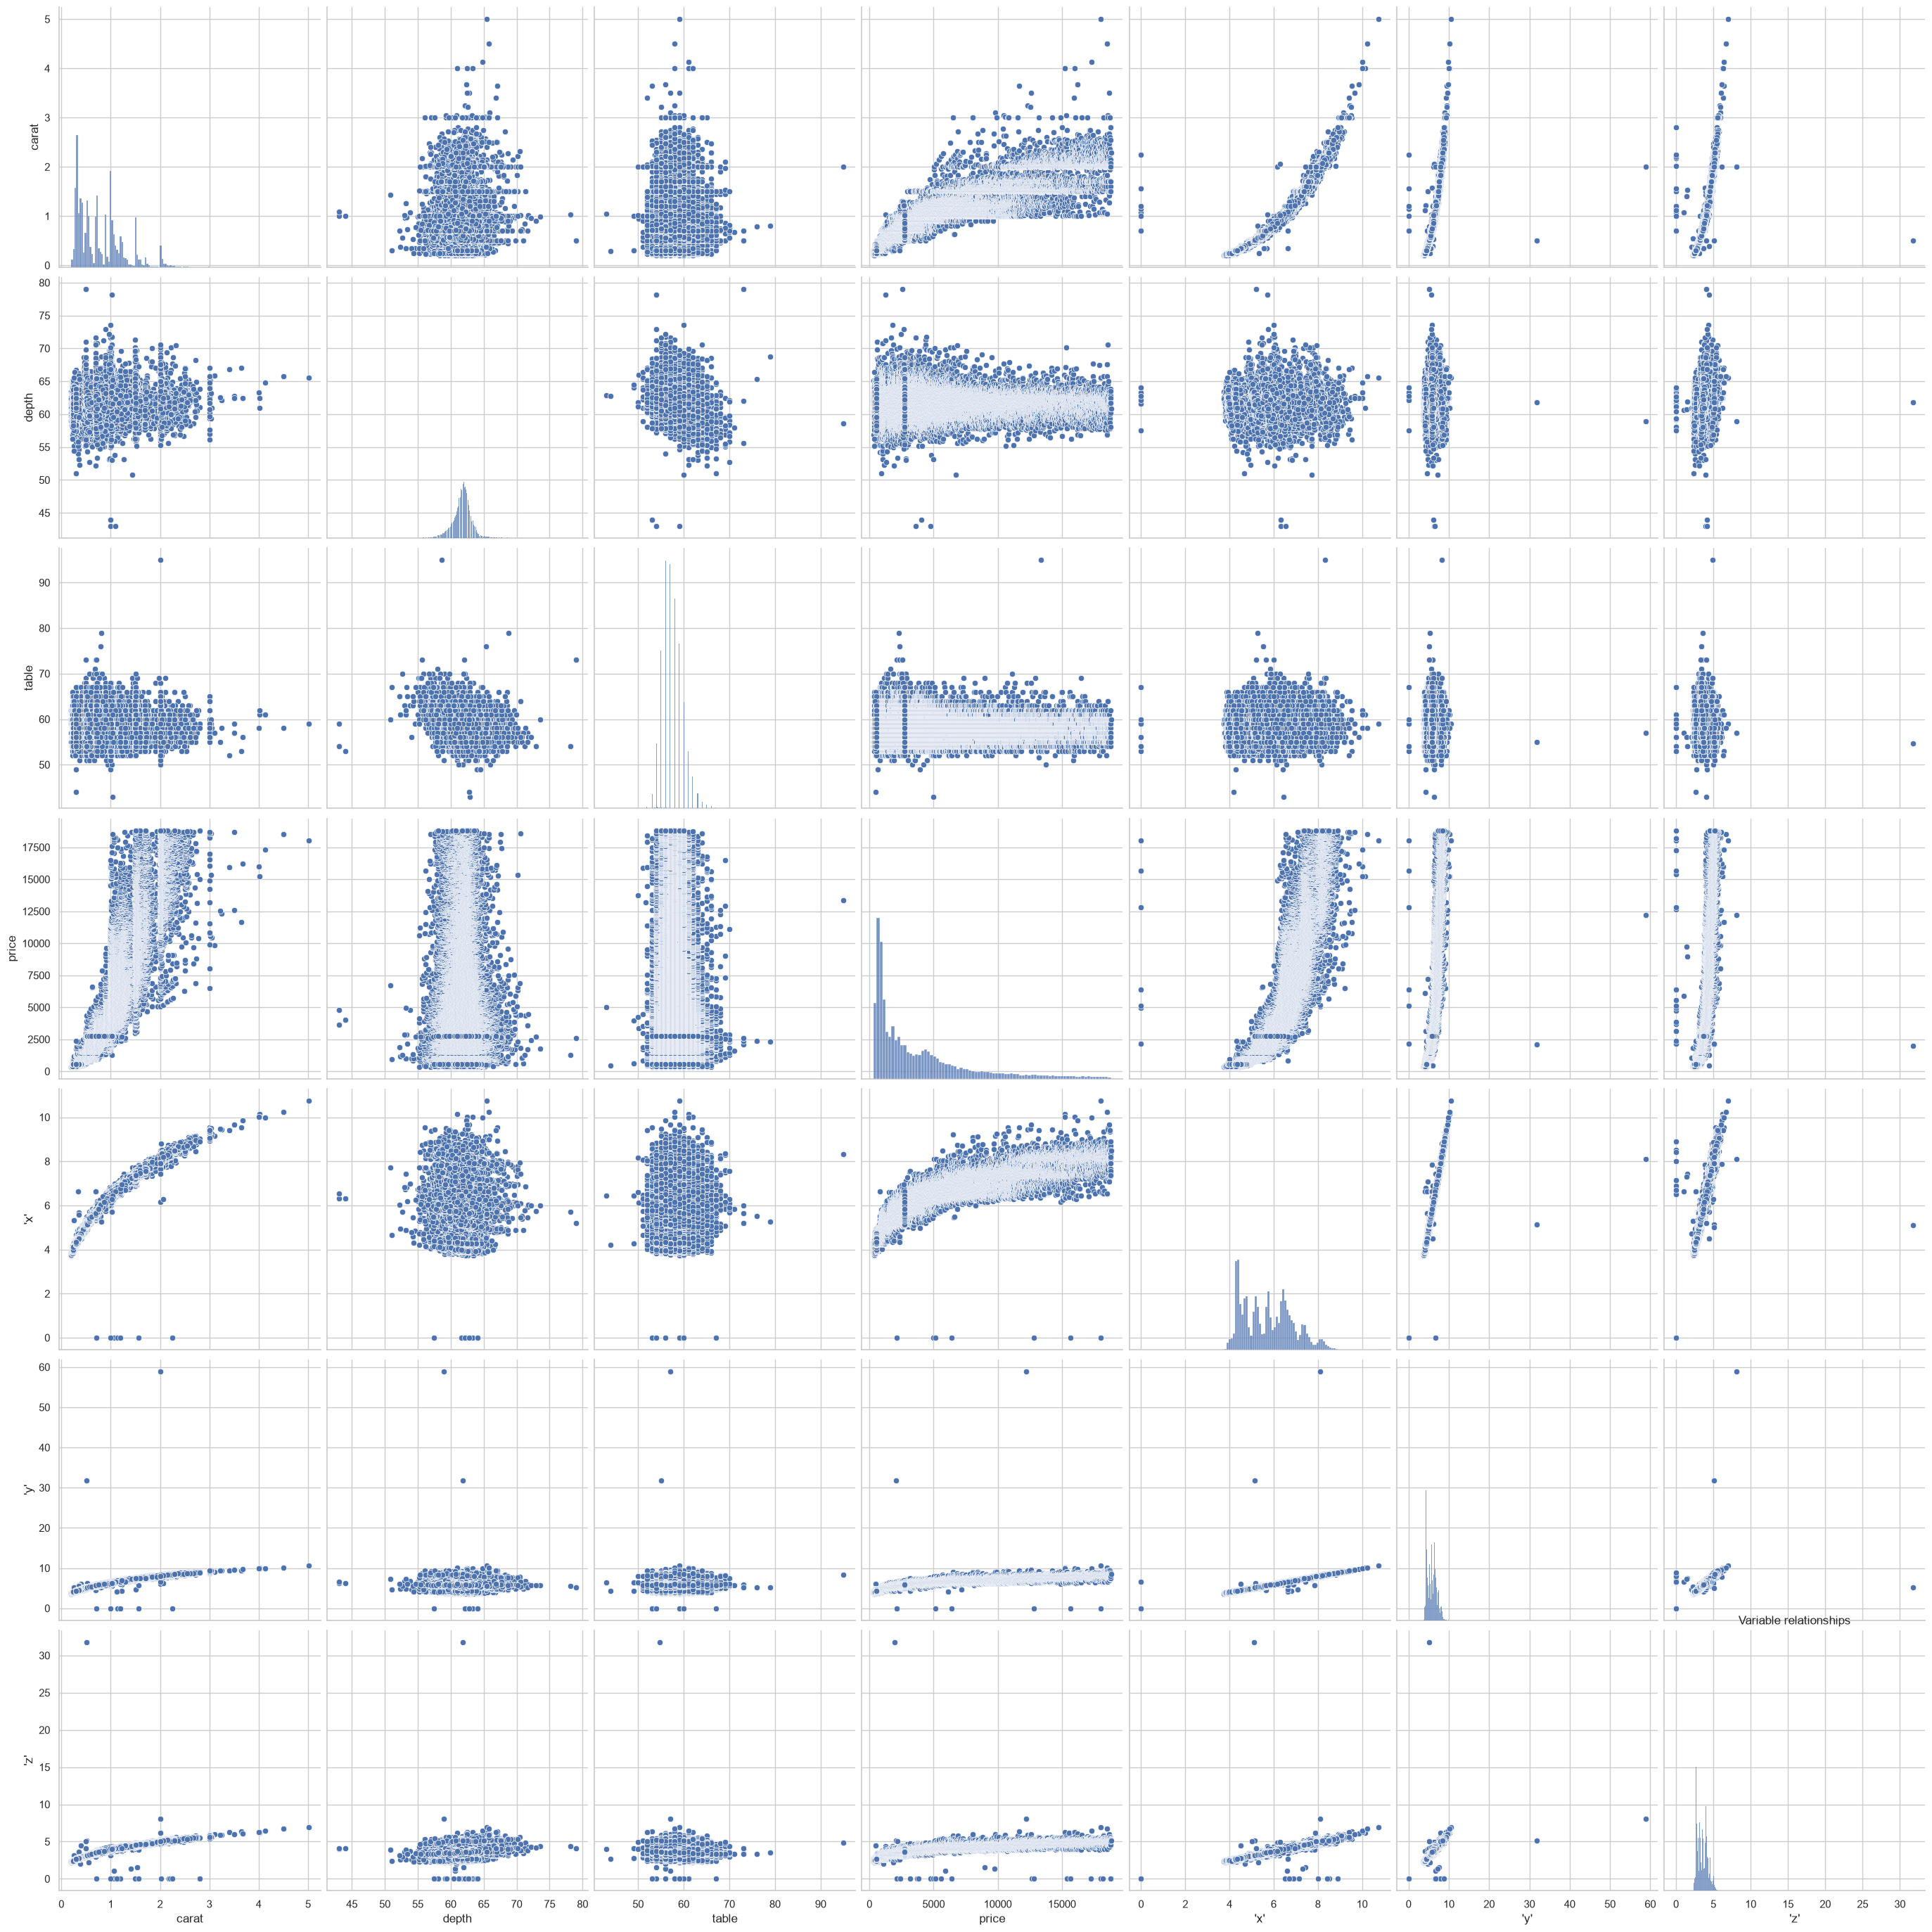

In [46]:
sns.pairplot(df[numeric_features], height=4)
plt.title("Variable relationships")
plt.show()


#### Numeric and categoric variables

For analyzing also ordinal variables with categoric variables, we are going to use grouped boxplots

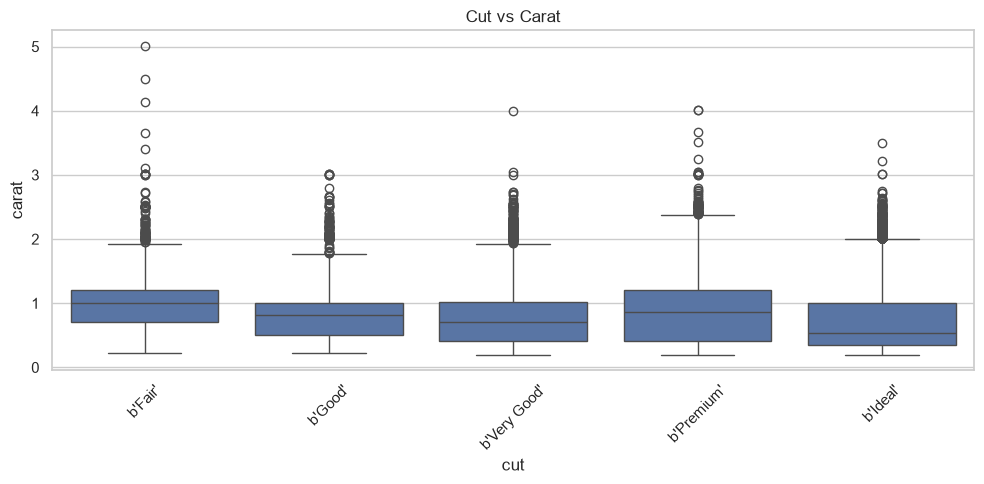

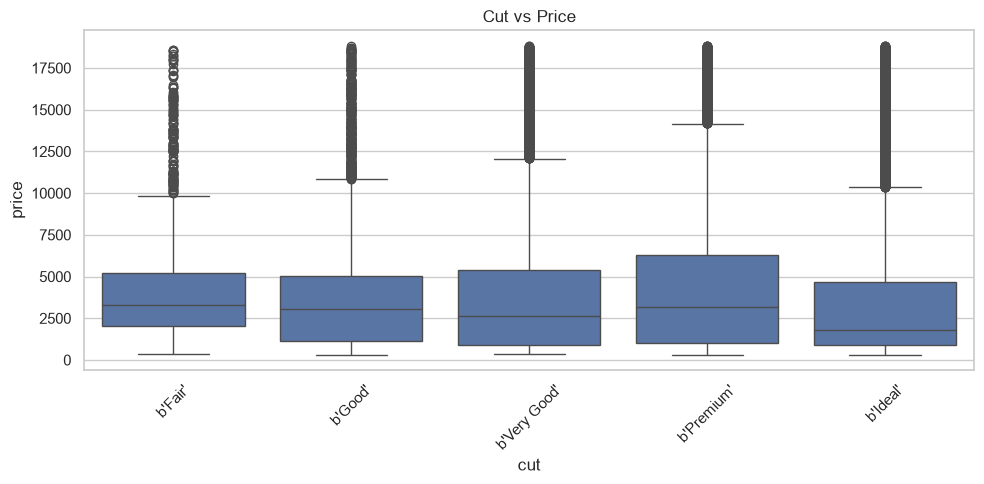

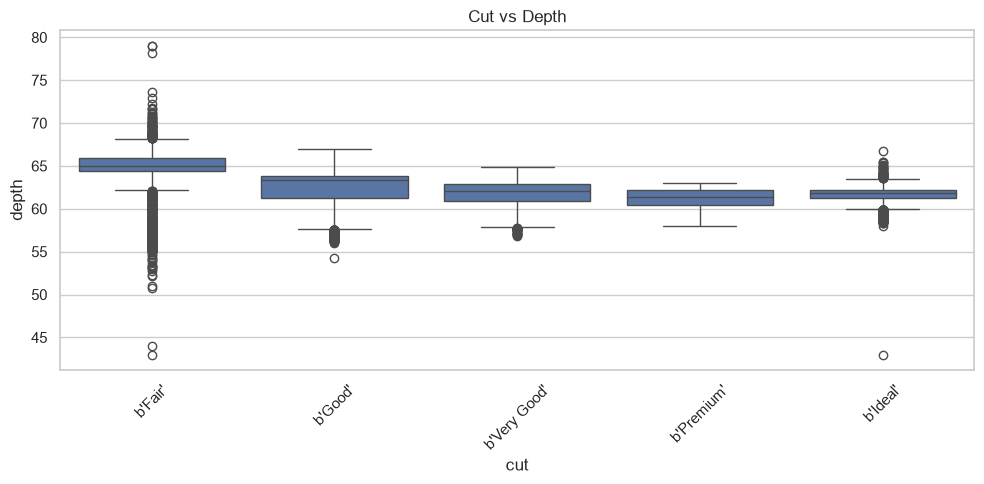

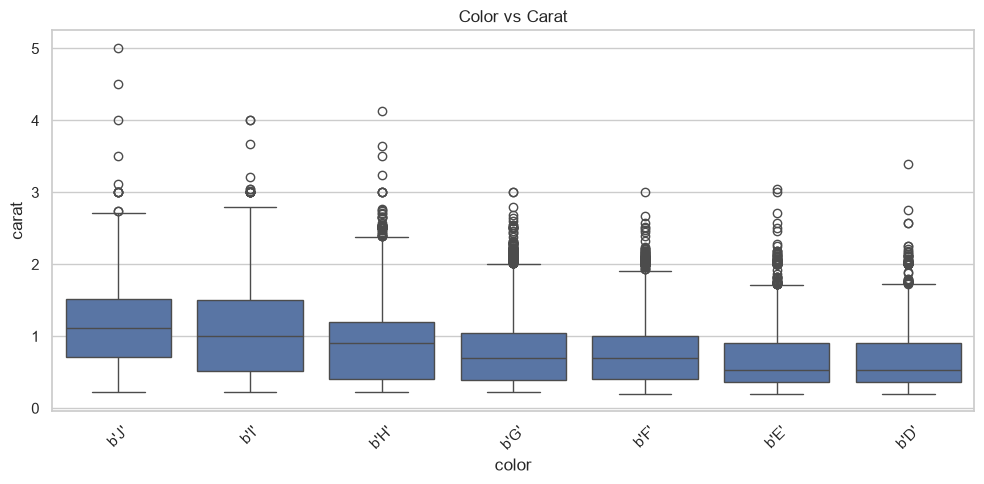

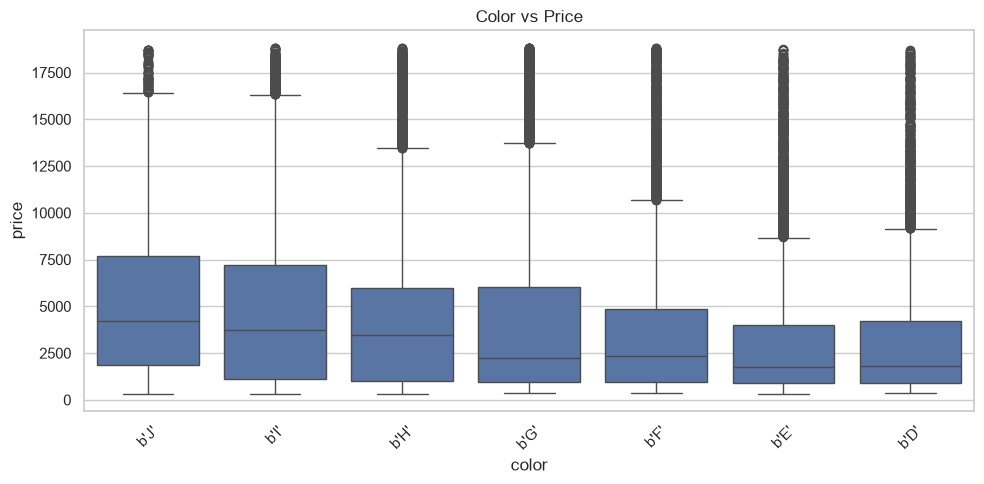

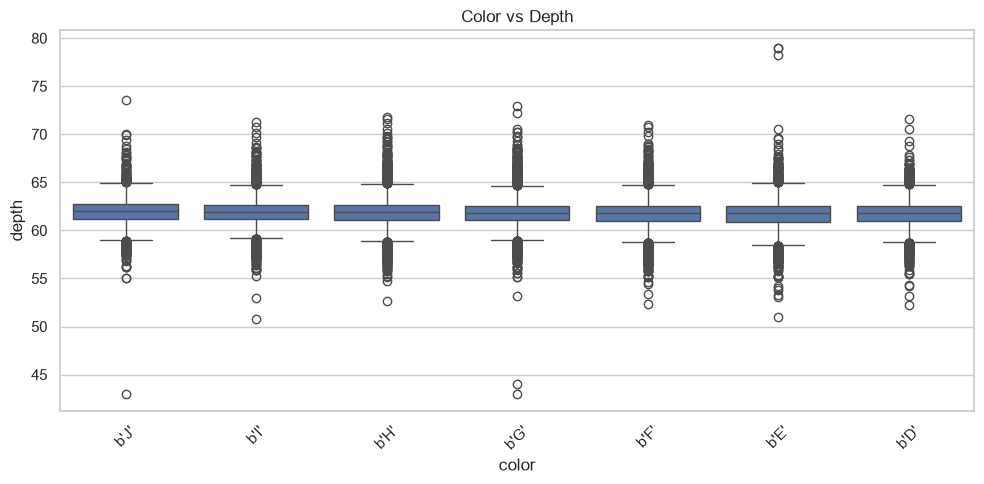

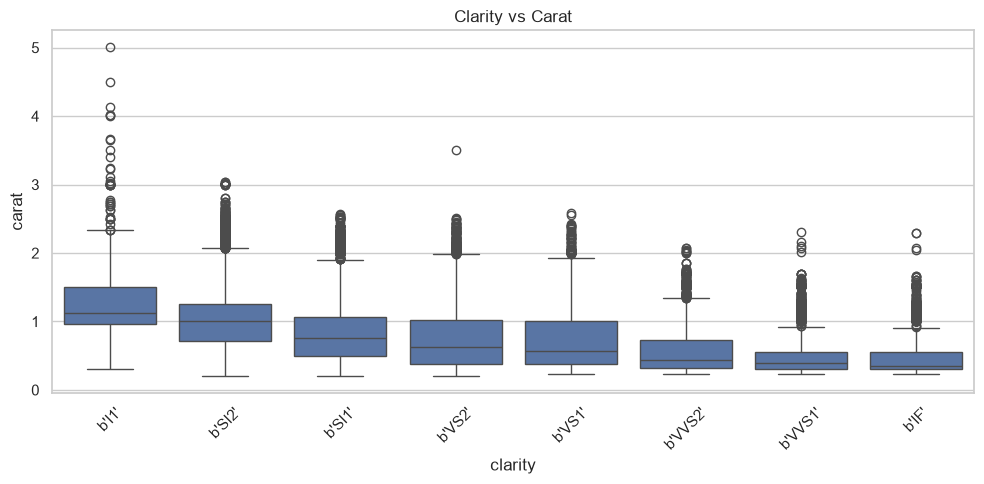

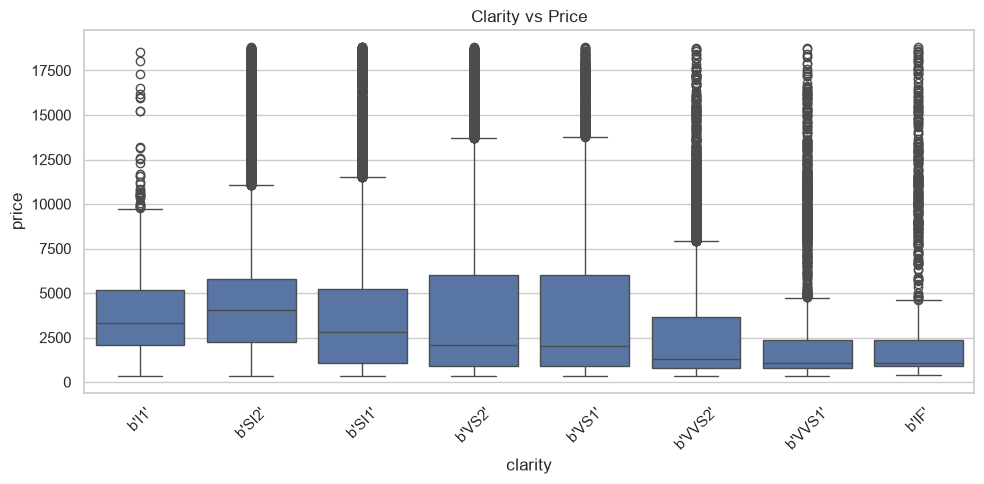

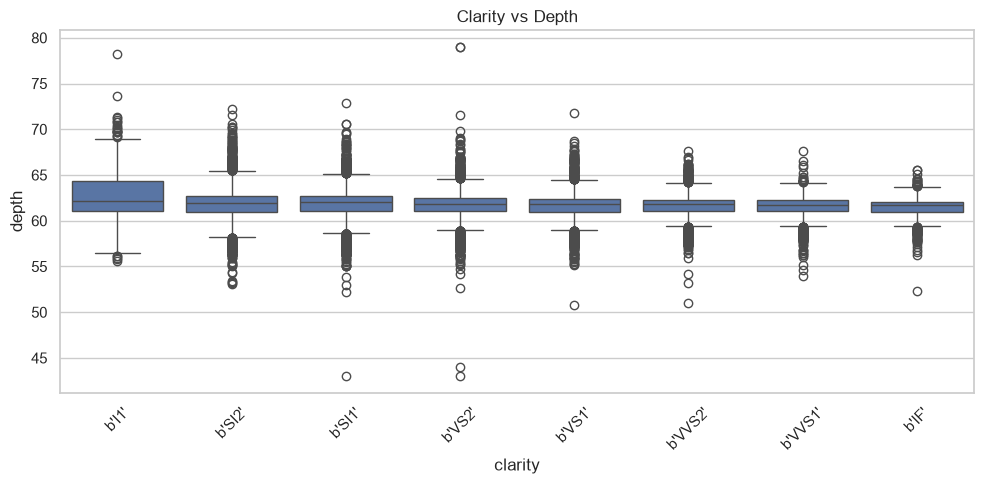

In [47]:
# Order of the ordinal features
ord_vars_orders = {
    'cut': ["b'Fair'", "b'Good'", "b'Very Good'", "b'Premium'", "b'Ideal'"],
    'color': ["b'J'", "b'I'", "b'H'", "b'G'", "b'F'", "b'E'", "b'D'"],
    'clarity': ["b'I1'", "b'SI2'", "b'SI1'", "b'VS2'", "b'VS1'", "b'VVS2'", "b'VVS1'", "b'IF'"]
}

# Create the groups
cat_num_groups = [('cut', 'carat'), ('cut', 'price'), ('cut', 'depth'), ('color', 'carat'), ('color', 'price'), ('color', 'depth'), ('clarity', 'carat'), ('clarity', 'price'), ('clarity', 'depth')]

for cat_col, num_col in cat_num_groups:
    plt.figure(figsize=(10,5))
    sns.boxplot(df, x=cat_col, y=num_col, order=ord_vars_orders[cat_col])
    plt.title(f"{cat_col.capitalize()} vs {num_col.capitalize()}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In these boxplots we can see that when a feature is compared with price, most of the instances are condensed in low prices, so diamonds that are unique stand out significantly in terms of price and become outliers.

When comparing with depth, we can see that most of them are condensed in average values and the ones that are to low or to high become outliers. 

Maybe could be also interesting to see which cut has the higher prices

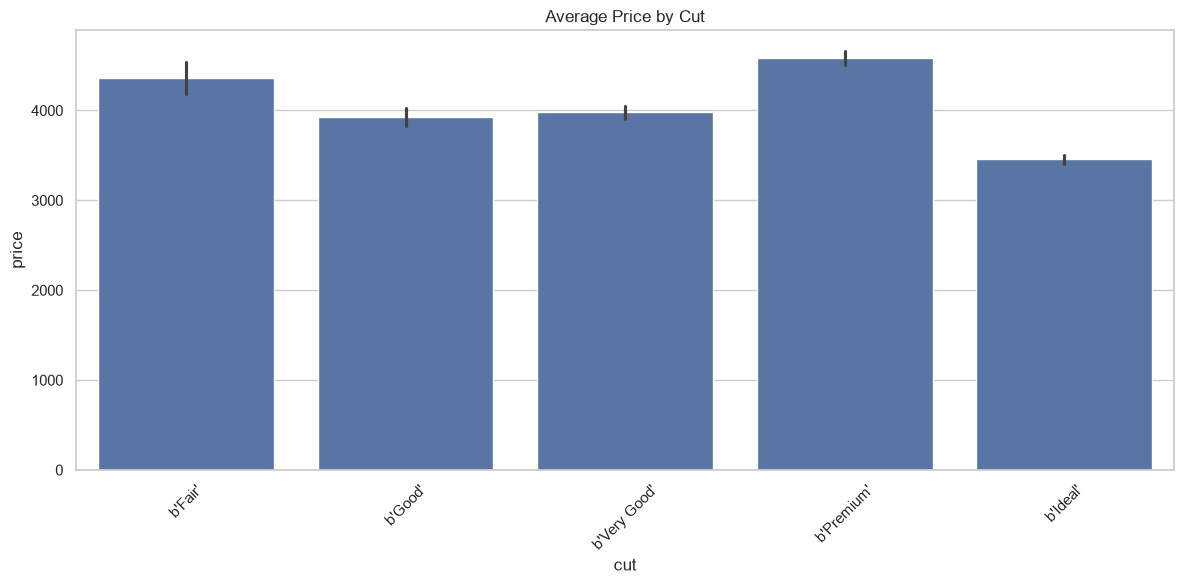

In [48]:
plt.figure(figsize=(12,6))
sns.barplot(df, x='cut', y='price', estimator=np.mean, order=ord_vars_orders['cut'])
plt.title(f"Average Price by Cut")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

If you analyze this graph, there is sometgins strange. As cut establishes how good a diamond is, what one would expect is that 'fair' has the lower prices and 'ideal' has the higher ones. 

However, we can see that 'premium' has higher prices than 'ideal' and 'fair' has higher prices than 'very good' and 'good'

A reasonable explanation would be that, in order to sell diamonds, fair diamonds are done bigger than ideal ones, that may be so small, so then the price is more balanced. 

In order to check this, we are going to compute price/carat and add it to the Dataframe, as it will be useful (I believe) for the model. 

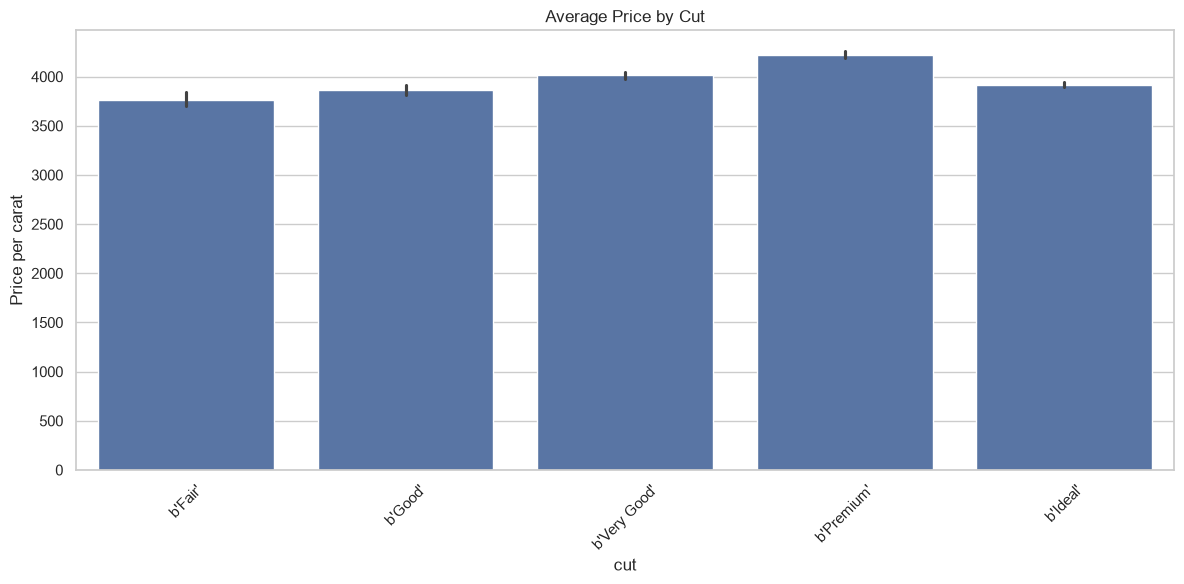

In [49]:
df['price_per_carat'] = (df['price'] / df['carat']).round(2)

numeric_features.append('price_per_carat')

plt.figure(figsize=(12,6))
sns.barplot(df, x='cut', y='price_per_carat', estimator=np.mean, order=ord_vars_orders['cut'])
plt.title(f"Average Price by Cut")
plt.ylabel("Price per carat")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This barplot has much more sense, as it is progressive from the worst to the best. There is only one exception with ideal, that has lower prices than premium. This difference could be explained with other features such as 'color' or 'clarity', that increases cut from 'premium' to 'ideal'.

#### Categoric and categoric variables

Finally, we have to study relationships between categoric variables

In order to do so, we are going to plot some heat maps and contingency tables.

Contingency table cut vs color
color          b'D'   b'E'   b'F'   b'G'   b'H'   b'I'  b'J'
cut                                                         
b'Ideal'      13.15  18.11  17.75  22.66  14.45   9.71  4.16
b'Premium'    11.62  16.95  16.90  21.20  17.11  10.35  5.86
b'Very Good'  12.52  19.86  17.91  19.03  15.10   9.97  5.61
b'Good'       13.49  19.02  18.53  17.75  14.31  10.64  6.26
b'Fair'       10.12  13.91  19.38  19.50  18.82  10.87  7.39


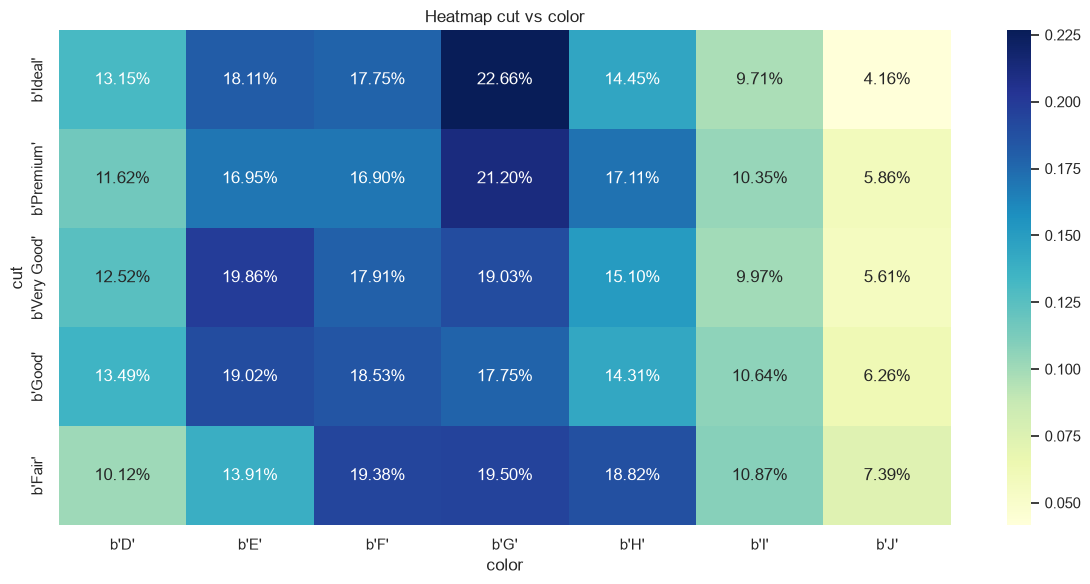

Contingency table cut vs clarity
clarity       b'IF'  b'VVS1'  b'VVS2'  b'VS1'  b'VS2'  b'SI1'  b'SI2'  b'I1'
cut                                                                         
b'Ideal'       5.62     9.50    12.09   16.65   23.53   19.87   12.06   0.68
b'Premium'     1.67     4.47     6.31   14.42   24.34   25.92   21.38   1.49
b'Very Good'   2.22     6.53    10.22   14.69   21.45   26.82   17.38   0.70
b'Good'        1.45     3.79     5.83   13.21   19.93   31.80   22.03   1.96
b'Fair'        0.56     1.06     4.29   10.56   16.21   25.34   28.94  13.04


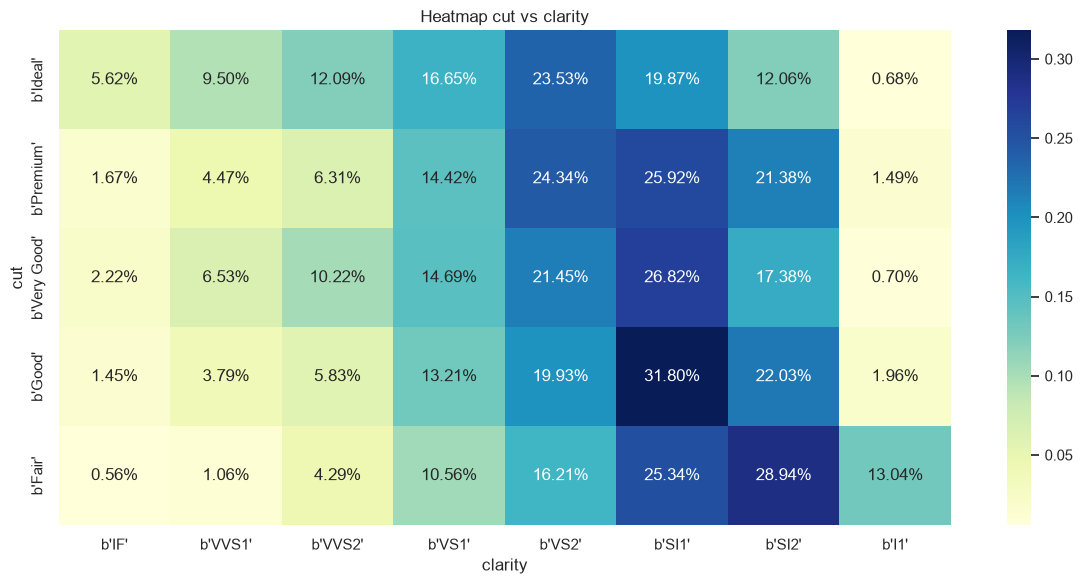

Contingency table color vs clarity
clarity  b'IF'  b'VVS1'  b'VVS2'  b'VS1'  b'VS2'  b'SI1'  b'SI2'  b'I1'
color                                                                  
b'D'      1.08     3.72     8.16   10.41   25.05   30.75   20.22   0.62
b'E'      1.61     6.70    10.12   13.08   25.21   24.76   17.48   1.04
b'F'      4.03     7.69    10.22   14.29   23.07   22.33   16.86   1.50
b'G'      6.03     8.85    12.78   19.02   20.78   17.50   13.71   1.33
b'H'      3.60     7.04     7.32   14.08   19.79   27.40   18.82   1.95
b'I'      2.64     6.55     6.73   17.74   21.56   26.26   16.82   1.70
b'J'      1.82     2.64     4.67   19.30   26.03   26.71   17.06   1.78


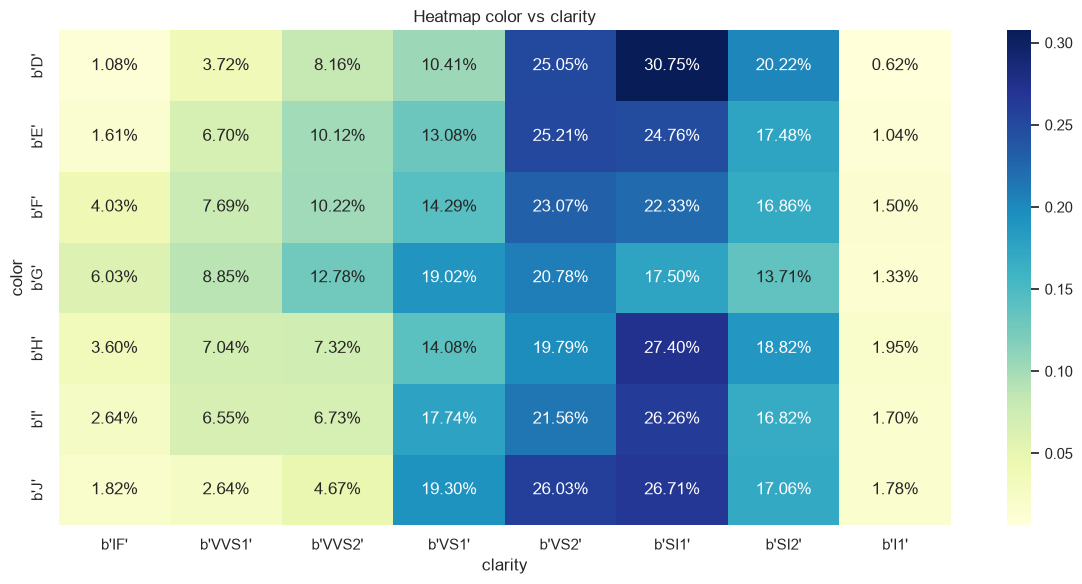

In [50]:
cat_cat_groups = [('cut', 'color'), ('cut', 'clarity'), ('color', 'clarity')]

for cat1, cat2 in cat_cat_groups:
    # Contingency table
    contingency_table = pd.crosstab(df[cat1], df[cat2], normalize='index')

    contingency_table = contingency_table.reindex(
        index=ord_vars_orders[cat1][::-1],
        columns=ord_vars_orders[cat2][::-1]
    )

    print(f"Contingency table {cat1} vs {cat2}")
    print((contingency_table * 100).round(2))

    # Heatmap
    plt.figure(figsize=(12,6))
    sns.heatmap(contingency_table, annot=True, fmt= ".2%", cmap='YlGnBu')
    plt.title(f"Heatmap {cat1} vs {cat2}")
    plt.tight_layout()
    plt.show()

Some conclusions are:
- Most diamonds are neither the best nor the worst in color; they fall somewhere in between
- Same with clarity

### 2.4. Multivariate analysis

The purpose of the multivariate analysis is to discover complex relationships between variables

#### Scatter plots with multiple dimensions

We are going to analyze the relationship between the most important features through a multi dimensional scatter plot

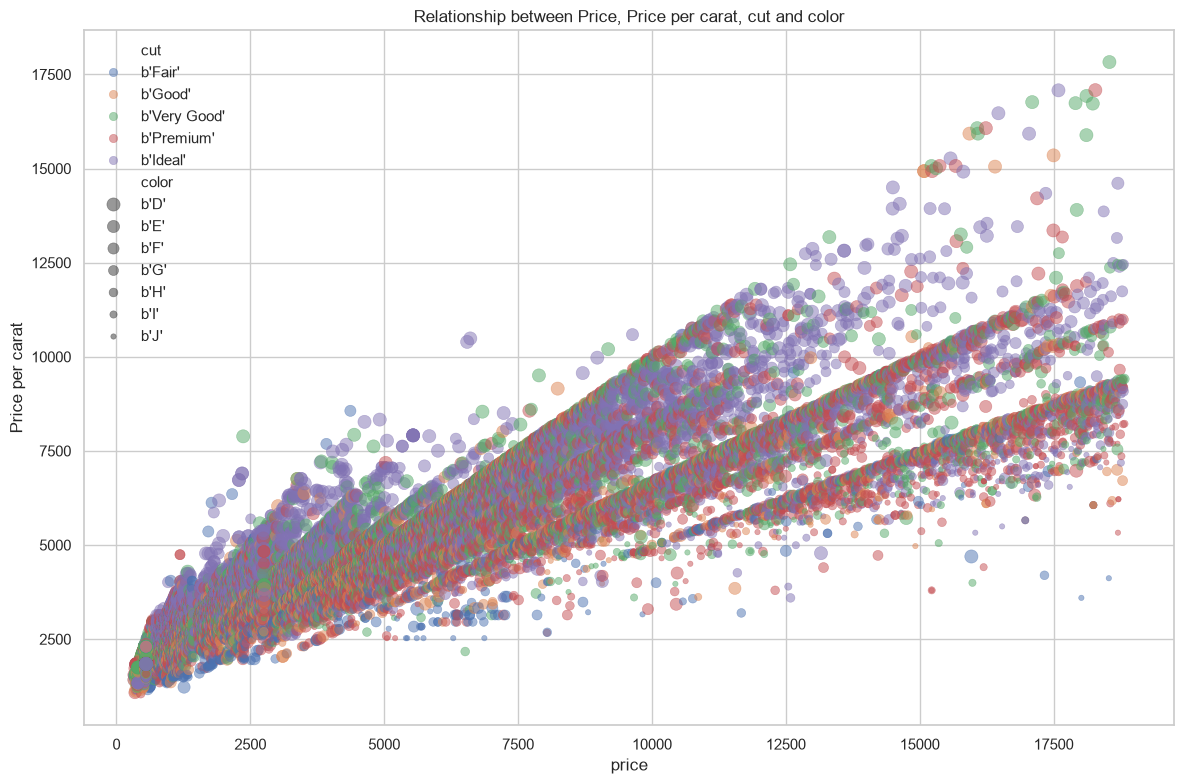

In [51]:
plt.figure(figsize=(12,8))
sns.scatterplot(df, x='price', y='price_per_carat', size='color',sizes=(15,90), size_order=ord_vars_orders['color'][::-1], hue='cut', hue_order=ord_vars_orders['cut'], alpha=0.5, edgecolor=None)
plt.ylabel("Price per carat")
plt.title("Relationship between Price, Price per carat, cut and color")
plt.tight_layout()
plt.show()

This graph shows expected behaviours:
1. When price per carat increases, price do so
2. When cut is better, price is higher
3. When color is better, price is higher

As a result, we have that the most expensive diamonds are the ones with a higher price per carat, better color and better cut. This means that on the top-right part of the graph we have a predominance of purple big dots. 

For representing numeric variables and see relationships with cut, we can do pair plots

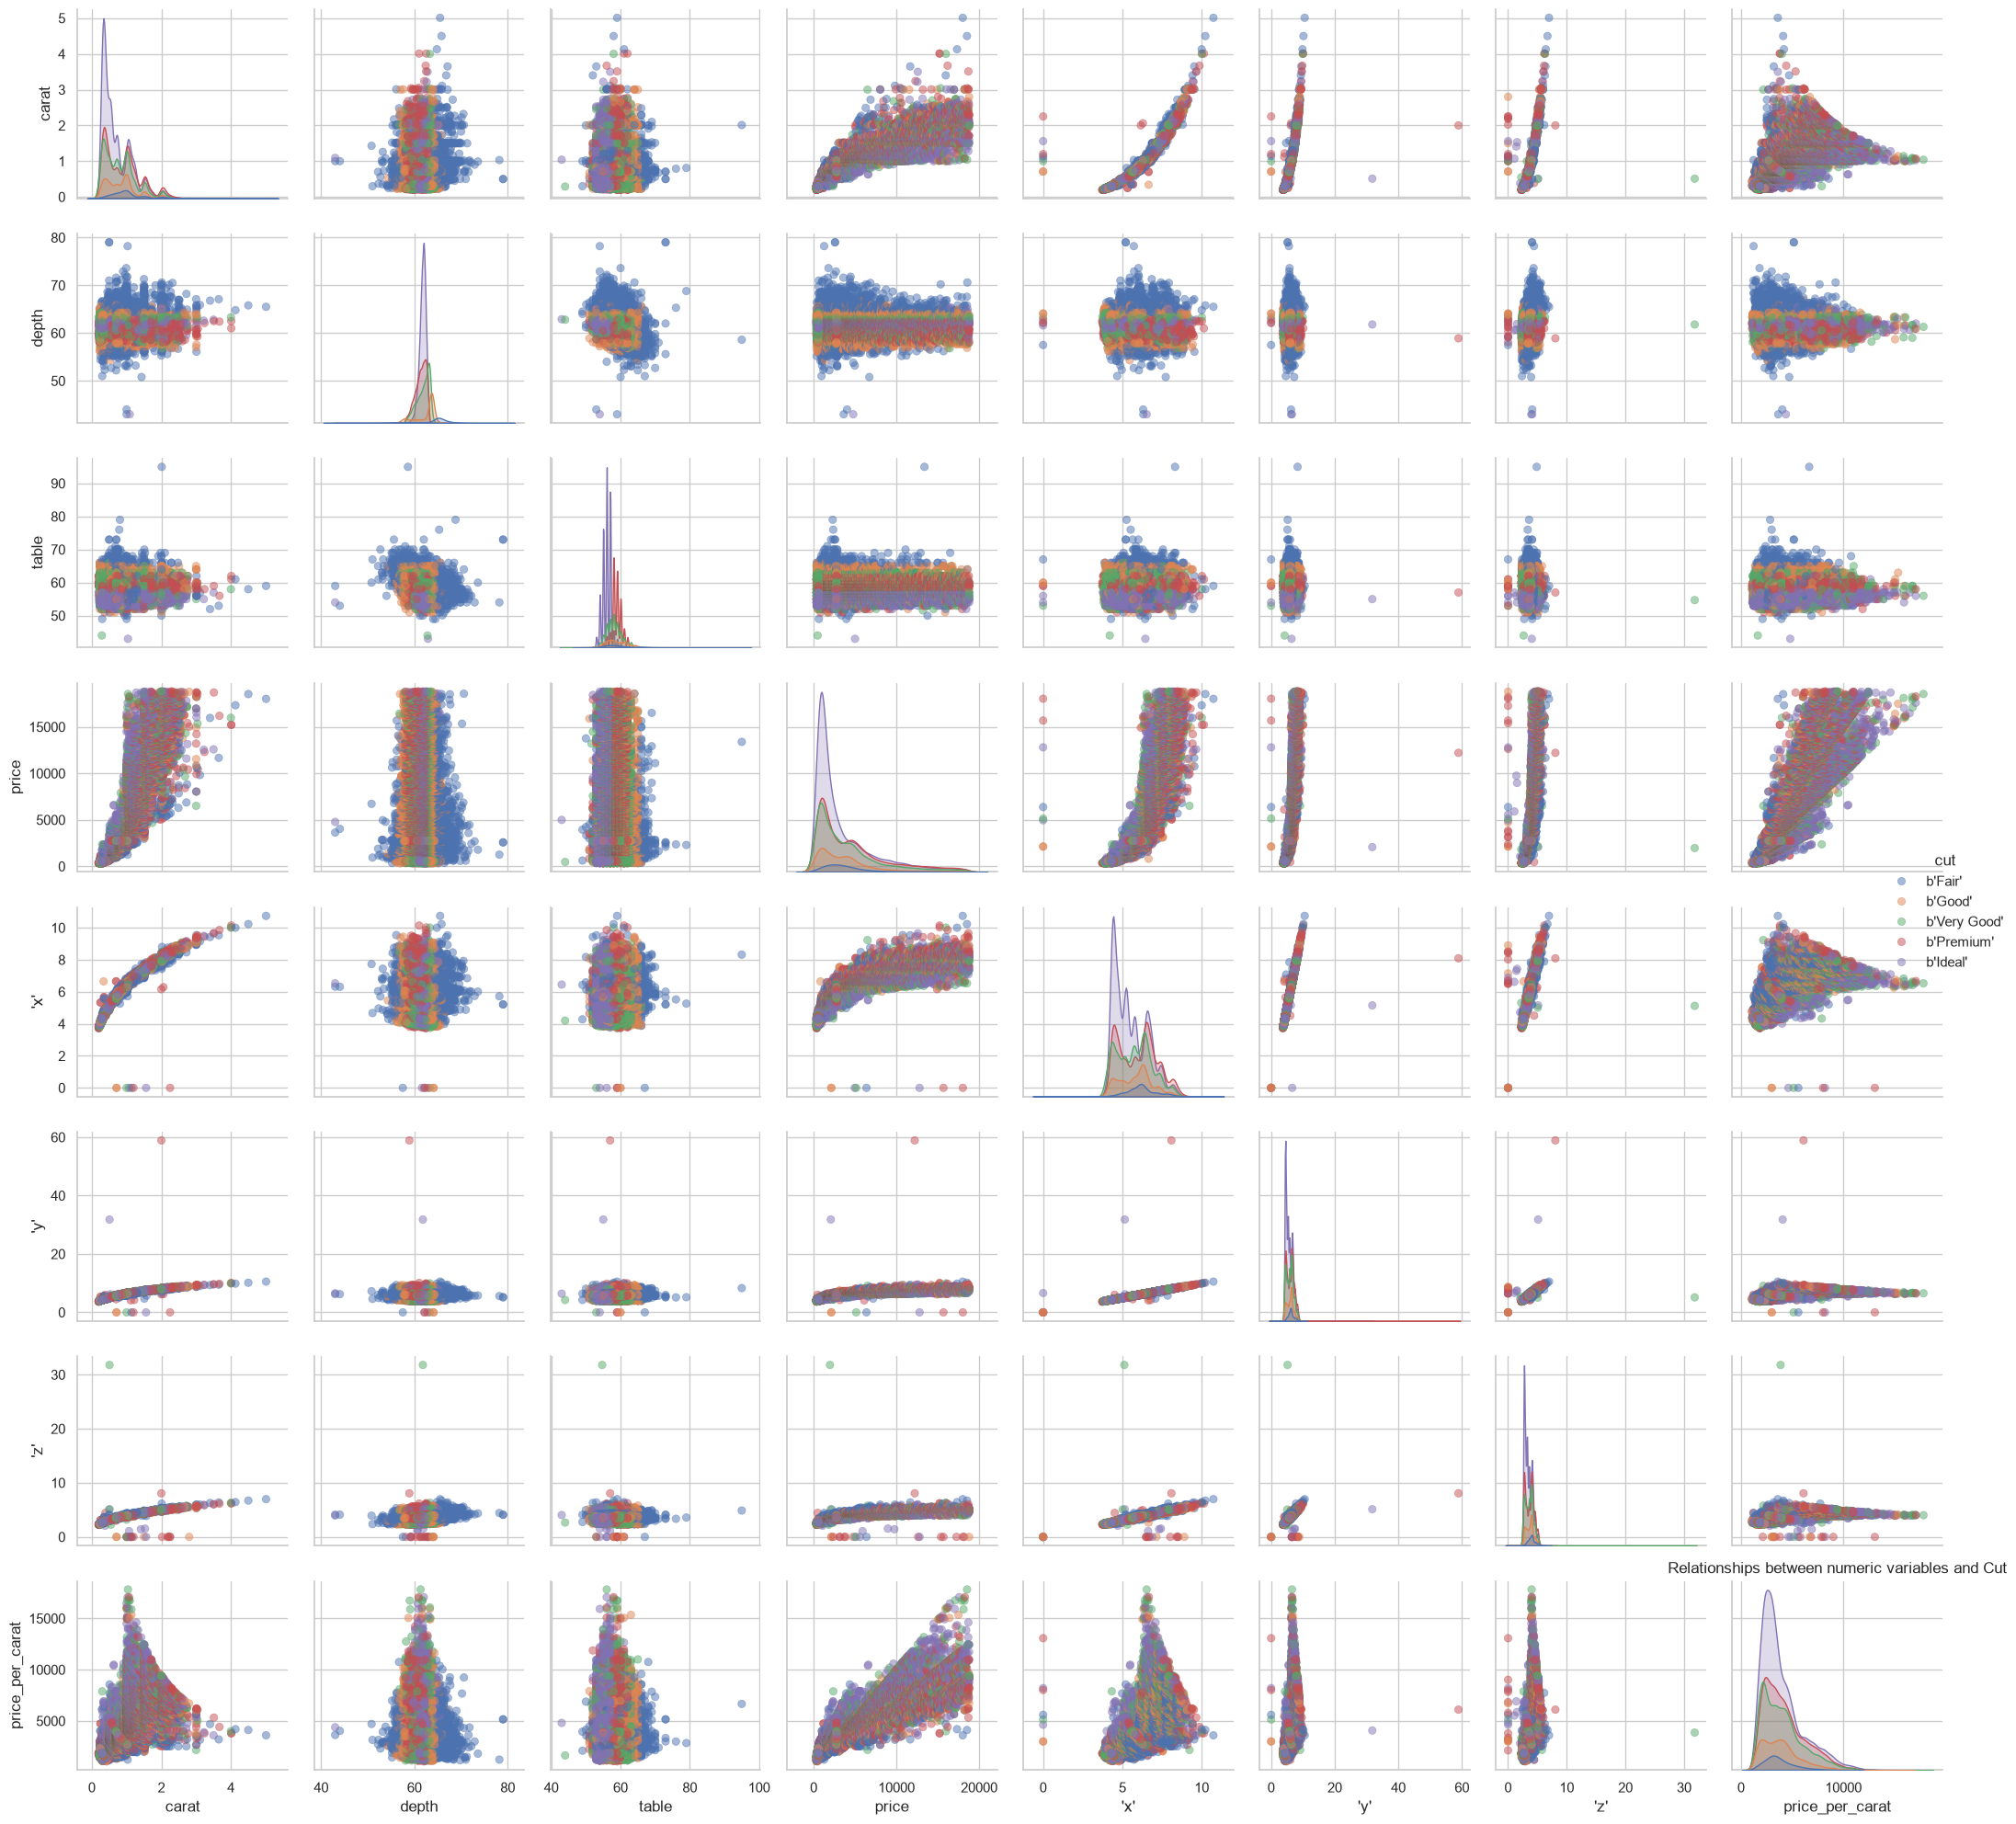

In [52]:
sns.pairplot(df[numeric_features + ['cut']], hue='cut', hue_order=ord_vars_orders['cut'], plot_kws={'alpha': 0.5, 'edgecolor': None})
plt.title("Relationships between numeric variables and Cut")
plt.tight_layout()
plt.show()

## 3. Preprocessing

When preprocessing data, it is important to know that some of the preprocessing must be done no matter what the model is, but there is another part of the preprocessing that depends on the model chosen. 

In our case, model-independent preprocessing include, for example, handling instances with x, y or z equal to 0. 

In the other hand, preprocessing that is dependent of the model includes handling outliers.

### 3.1. Model-independent preprocessing

As we said, we have to treat wrong values. For deciding which strategy use, we have to measure some things, as the number of wrong values. 

We know that any of the numeric features can have values equal to 0, as it has no sense, so we are going to check how many incorrect values are there. 

In [53]:
print((df[numeric_features] == 0).sum())

# See how many rows are affected
incorrect_rows = (df[numeric_features] == 0).any(axis=1).sum()
print(f"Number of rows affected: {incorrect_rows}")

carat               0
depth               0
table               0
price               0
'x'                 8
'y'                 7
'z'                20
price_per_carat     0
dtype: int64
Number of rows affected: 20


This means there are rows where there is more than one incorrect value.

We should know what percentage of the data is this

In [54]:
print(f"Percentage of rows with incorrect values: {round((incorrect_rows / df.shape[0]) * 100, 3)}%")

Percentage of rows with incorrect values: 0.037%


As the percentage is too low, we can asume deleting that rows, even if we lose some data, as deleting them might have a better effect that replacing the values. 

In [55]:
df = df[~(df[numeric_features] == 0).any(axis=1)].reset_index(drop=True)

# New stats
print(f"New dataset shape: {df.shape}")
print(f"Remaining zeroes in numeric features: {(df[numeric_features] == 0).sum().sum()}")

New dataset shape: (53920, 11)
Remaining zeroes in numeric features: 0


### 3.2. Model-dependent preprocessing

There are some decisons in preprocessing that depends on the model we choose. For example, outliers must be treated different depending on the model we choose. Some algorithms does not need that outliers are treated, and others need to. 

Also, the decision of which model should we use must be based on what we have seen in EDA. 

As we will see later, we are going to use nested cross validation to train the model. This have some implications, for example:

Imagine that you want to replace a value during preprocessing with the mean. If you take all the data and compute the mean to replace the value, you are using data that is going to be part of the test set. This means you are causing a data leak.

Now imagine that, in order to solve that, you split your data into train and test set, and then compute the mean with the train set only. If you think about nested cross validation, in each iteration of the outer loop, test set changes, so that means that you are computing the mean suposing that the train set will always be the same, so again, you are causing data leak. 

This introduces the necessity to use **pipelines** in order to avoid data leakage. 

<img src="../../images/cross_validation_image.png" alt="nested cross validation" style="width: 40%; height: auto;">

#### Choose the model

To do so, we are going to start analyzing outliers. 

We can observe outliers in all the numeric features, but there are not errors. For example, outliers in price indicates that the diamond is much better than others, and outliers in features related with size indicates that the diamonds are simply bigger. 

For this reason, we can't just replace the value with the median, for example. Neither with the upper or lower bound, as the model would not capture certain trends or patterns in the data. 

The other option is choose a model that is not sensible to outliers. That type of models are tree-based ones. 

Another thing we have to check is multicolineality. We can observe that it actually exists between carat, x, y and z mainly. This is another sign that we have to use tree-based models. Later, we could try also to change features deleting features x, y and z and replacing them by volume = x * y * z. 

Inside tree based models, we can look, for example, to the size of the dataset to decide which one use. In our case, the dataset has approximately 54K instances, so it is big enough to take into account computational cost. 

For this reason, we could try LightGBM (or its Scikit-Learn implementation, HistGradientBoosting) or CatBoost better rather than models like Random Forest. They have also another benefit and it is that they can deal with categoric features without applying one-hot encoding. 

This decision simplifies a lot preprocessing until almost having no neccesity to do more preprocessing (in this simple case), as tree-based models are not sensitive to outliers, can deal with categoric features (but we need to determine the order of the ordinal features) and do not need to scale data, as they work with conditions of the type: x > c.

## 4. Train the model

So, the next thing to do is to separate the target column from the rest of the dataset, determine the order of the ordinal features, build the pipeline and train the model. 

In [58]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

# Set ordinal features as they are
ordinal_features = ["cut", "color", "clarity"]

# Separate 'cut' from the dataset
X = df.drop(columns=["cut"])

# Map 'cut' values to numbers
cut_map = {cut_class : i for i, cut_class in enumerate(ord_vars_orders["cut"])}
y = df['cut'].map(cut_map).astype(int)

cat_cols = ordinal_features.copy()
cat_cols.remove('cut')

# Preprocessing (of the ordinal features)
preprocessor = ColumnTransformer(
    transformers=[
        ('ord', OrdinalEncoder(categories=[ord_vars_orders['color'], ord_vars_orders['clarity']], handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
        ('num', 'passthrough', numeric_features)
    ],
    remainder='drop'
)

# Pipeline
pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', HistGradientBoostingClassifier(
            categorical_features=[0,1],
            random_state=42
        ))
    ]
)

# Hyperparameters
# param_grid = {
    # 'classifier__learning_rate' : [i/100 for i in range(1, 100, 1)],
    # 'classifier__max_iter' : [i for i in range(100, 150, 10)],
    # 'classifier__max_leaf_nodes' : [i for i in range(25, 65, 5)],
    # 'classifier__min_samples_leaf' : [i for i in range(20, 50, 5)]
# }

param_grid = {
    'classifier__learning_rate' : [0.03, 0.08, 0.15],
    'classifier__max_iter' : [100, 150],
    'classifier__max_leaf_nodes' : [31, 45, 63],
    'classifier__min_samples_leaf' : [20, 40]
}

# Divide the dataset into 5 folds (in each iteration, 1 will be test set and the others, train set)
cv_outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Divide the train set into 3 folds, for training and validation set for hyperparameter fine-tuning
cv_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

inner_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv_inner,
    scoring='f1_weighted',
    n_jobs=-1
)

outer_scores = cross_val_score(
    estimator=inner_search,
    X=X,
    y=y,
    cv=cv_outer,
    scoring='f1_weighted',
    n_jobs=-1
)

print(f"Puntuation in each Outer Loop: {outer_scores}")
print(f"Unbiased average performance: {outer_scores.mean():.4f} (+/- {outer_scores.std():.4f})")



Puntuation in each Outer Loop: [0.80551883 0.80514993 0.80316013 0.79647952 0.79756366]
Unbiased average performance: 0.8016 (+/- 0.0038)


## 5. Evaluation

We are using Weighted F1 Score for evaluating the model. For F1 Score in Multiclass Classification problem, there are two types:

- Macro averaging calculates the metric independently for each class and then takes the unweighted arithmetic mean across all classes
- Weighted averaging calculates the F1-score for each class and then takes the weighted mean, using the support (the true number of instances of each class in the dataset) as the weight

As it is not so important to detect Fair class for example, not as much as fraud detection or cancer detection, we are going to use Weighted F1 Score. 

For the best configuration of hyperparameters, we obtain a score of 0.81. We will see if we can make this score better. 

The first thing we are going to do is to change x,y and z by volume. 

Not only we can do changes in the data, but also in the model we are using. 